In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

In [14]:
iris=load_iris()
X=iris.data
y=iris.target #orginally are 0,1,2 for three species of iris flowers

# Convert to pandas DataFrame for table illustration

df=pd.DataFrame(X,columns=iris.feature_names)
df['species']=[iris.target_names[i] for i in y]
#set the species column and replace 0, 1, 2 with actual names of the species

df

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,virginica
146,6.3,2.5,5.0,1.9,virginica
147,6.5,3.0,5.2,2.0,virginica
148,6.2,3.4,5.4,2.3,virginica


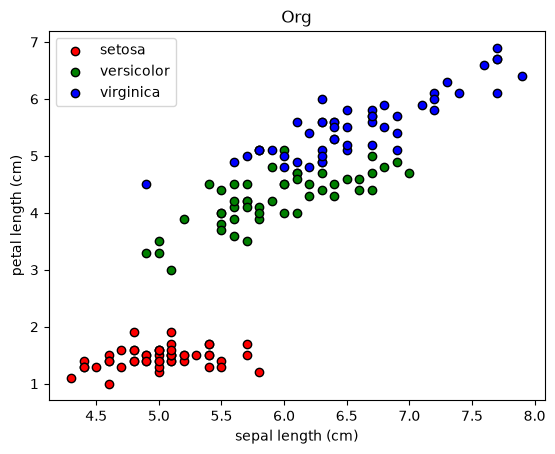

In [15]:
colors=['red','green','blue']
for i,color in enumerate(colors): #get the index and color of each species
    plt.scatter(X[y==i,0],X[y==i,2],c=color,label=iris.target_names[i],edgecolors='k')
    #x-axis:first feature, y-axis: third feature
    #edgecolor = 'k' --> add black edge on each dot

plt.xlabel(iris.feature_names[0])
plt.ylabel(iris.feature_names[2])
plt.title('Org')
plt.legend()
plt.show()

In [16]:
#split dataset into (x/y) training and testing sets
#test_size = 0.3 -->30% of the dataset for testing other for training 
#random state --> set random seed for same results each time
#stratify = y --> ensure proportion of the training and testing sets remains 1:1:1 for each species (y)
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.3,random_state=42,stratify=y)

In [17]:
#Standardization --> rescale the all datas into the range of 0~1
from sklearn.preprocessing import StandardScaler

#StanderScaler() --> (data-maen)/stander deviation
#and let the result --> mean=0, standard deviation=1
sc=StandardScaler()

#fit --> caculate the mean and standard deviation of the training set
#transform --> replace the training set with data after fitting
X_train=sc.fit_transform(X_train)

#<only transform> --> for testing only use the mean and std of the training set
#cause we cannot get the answer in advanced
X_test=sc.transform(X_test)

##Costom Gaussian NB function

In [ ]:
class CustomGaussianNB:
    def fit(self, X, y):
        #predict means, variances, priors first
        self.classes = np.unique(y) #find out all differ elements and list from small to big
        self.variances ={}
        self.means = {}
        self.priors = {}

        for i in self.classes:
            X_i = X[y==i]
            self.means[i] = np.mean(X_i, axis = 0)
            self.variances[i] = np.var(X_i, axis = 0)

            #without considering any feature --> num of specific species / total num of flowers
            #X.shape -->(rows num{total num, 0}, cloumns num{features num, 1})
            #i -> choose specific feature to get the total num
            self.priors[i] = X_i.shape[0] / float(X.shape[0])
            #add float to get ans in float

    def _caculate_likelihood(self, class_index, x):
        mean = self.means[class_index]
        var = self.variances[class_index]

        eps = 1e-9 
        #by adding small number to incase error {if var == 0 }
        #because denominator cannot be zero
        a = np.exp(-((x-mean)**2)/(2*var + eps))
        b = np.sqrt(2 * np.pi * var + eps)
        return a / b

    def predict(self, X_test_data):
        predictions = []
        for x in X_test_data:
            posteriors = []
            for i in self.classes:
                prior = np.log(self.priors[i])
                likelihood = np.sum(np.log(self._caculate_likelihood(i, x)))
                posterior = prior + likelihood
                posteriors.append(posterior)
            predictions.append(self.classes[np.argmax(posteriors)])
        return np.array(predictions)

In [27]:
# Build a Naive Bayes classifier using GaussianNB

classifier=CustomGaussianNB()

#fit the training set to the model
classifier.fit(X_train,y_train)

#predict the testing set
y_pred=classifier.predict(X_test)

#target_names=iris.target_names --> ['setosa', 'versicolor', 'virginica']
print(classification_report(y_test,y_pred, target_names=iris.target_names))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.82      0.93      0.88        15
   virginica       0.92      0.80      0.86        15

    accuracy                           0.91        45
   macro avg       0.92      0.91      0.91        45
weighted avg       0.92      0.91      0.91        45



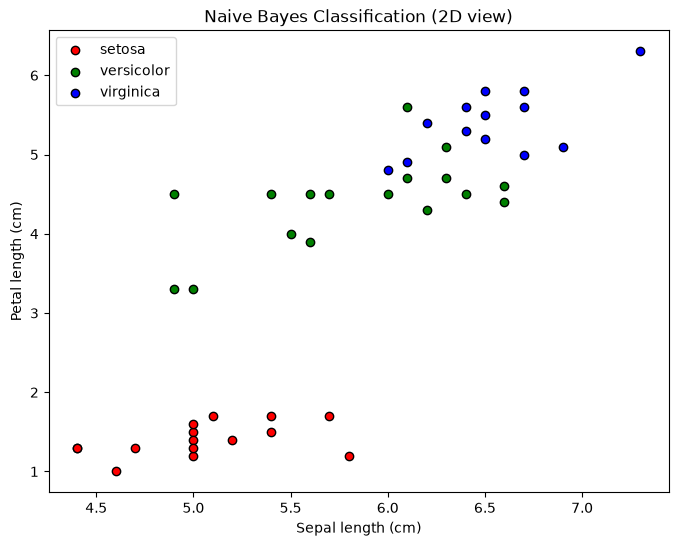

In [32]:
fig = plt.figure(figsize=(8, 6))
#turn the standardized data back to the original data 
X_test_original = sc.inverse_transform(X_test)

for i,color in enumerate(colors):
    plt.scatter(X_test_original[y_pred==i,0],X_test_original[y_pred==i,2],c=color,label=f"{iris.target_names[i]}",edgecolors='k')


plt.xlabel('Sepal length (cm)')
plt.ylabel('Petal length (cm)')
plt.title('Naive Bayes Classification (2D view)')
plt.legend()
plt.show()

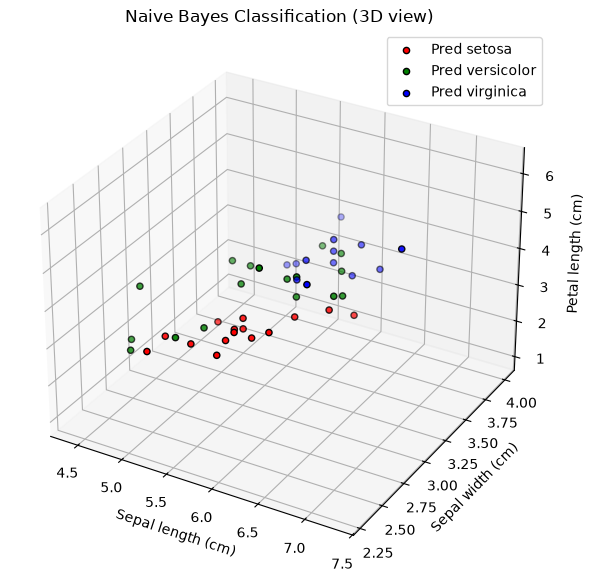

In [34]:
fig = plt.figure(figsize=(9, 7))
ax=plt.axes(projection='3d')
for i,color in enumerate(colors):
  ax.scatter(X_test_original[y_pred==i,0],X_test_original[y_pred==i,1], X_test_original[y_pred==i,2],c=color,label=f"Pred {iris.target_names[i]}",edgecolors='k')
  
ax.set_xlabel('Sepal length (cm)')
ax.set_ylabel('Sepal width (cm)')
ax.set_zlabel('Petal length (cm)')
ax.set_title('Naive Bayes Classification (3D view)')
ax.legend()

In [ ]:
"""
1. It is called "naive" because it naively assumes input features are completely independent of each other given the class label.
    In reality, features are often highly correlated.
    Still useful because relative ranking of classes usually remains correct.
    It also reduces complex probability calculations, preventing overfitting on small datasets.

2. [ exp(-((x-mean)**2)/(2*var)) ] / [sqrt(2 * np.pi * var)]
    Mean : average value
            --> sum of all values/num of items = ave
    Variance : dispersion (離散程度) of specific species
                --> ex: small means data are highly consistent, clustered together

3. most accurately : Setosa --> Precision,Recall,F1-score = 1.00 (100%)
    most confused : Vericolor and Virginica 

    In 2D plot, Setosa is totally separable from the other two species.
    And Versicolor and Virginica share a significant feature overlap in graph.
    Their Gaussian probability is similiar to each other which causes hard to distinguish in NB model.
"""
